# Causal Steering — andamento

**Dissertação de mestrado (PPGCC/PUCRS).** Continuação do estudo de *Feature Discovery*.
Lá mostramos, de forma **correlacional**, que existe uma **feature/direção de abstenção**
no modelo (que prevê quando ele responde *NOT ENOUGH EVIDENCE*) e que ela **generaliza**
entre datasets. Aqui damos o passo que fecha a RQ2: **provar que essa direção *causa* a
abstenção** — não apenas a acompanha.

> Modelo: **Llama-3.1-8B-Instruct** (4-bit), intervenção na camada **15**.


> **Atualização (27/09/2026):** resultados obtidos com o **SAE/direção v1**. Serão refeitos no **v3** (ver `../02-sae-v3.ipynb`), incluindo steering com a feature 19219.

## 1. Correlação não é causalidade — o que falta provar

No notebook anterior mostramos que a direção de abstenção **separa** abstém vs decisivo
(AUC ~0.84) e que a feature 22280 **ativa mais** quando o modelo abstém. Mas isso é
**correlação**: a direção pode ser só um *efeito colateral* de o modelo já ter decidido
abster, e não a *causa* da decisão.

O teste padrão de causalidade em interpretabilidade é o **activation steering** (adição
de ativação): **intervir** na direção e ver o comportamento mudar [Turner et al., 2023;
Panickssery et al., 2023]. É exatamente o que [Arditi et al., 2024] fazem para a recusa
— adicionar a direção induz recusa; removê-la a suprime. Aplicamos a mesma lógica à
abstenção:

> Durante a geração, somamos **α · (direção de abstenção)** ao *residual stream* da
> camada 15. Se a direção **causa** a abstenção, então **α > 0 deve induzir** abstenção
> (fazer o modelo abster em claims que decidiria) e **α < 0 deve suprimir** (fazer o
> modelo decidir em claims que absteria). Uma curva dose-resposta monotônica = evidência
> causal.


## 2. Metodologia (direto ao ponto)

- **Direção.** A mesma direção de abstenção do estudo anterior: **diferença de médias**
  (média das ativações quando abstém − média quando decide), na camada 15, estimada nas
  ativações de treino (VitaminC/FEVER). É um vetor único; a unidade "α = 1" equivale a
  somar **um gap médio** entre abster e decidir.
- **Intervenção.** Um *hook* na saída da camada 15 soma `α · direção` a **todas as
  posições** durante a geração do veredito (greedy). Nada mais é alterado.
- **Amostra.** 200 claims do **AVeriTeC** (dataset-alvo). Para cada α, geramos o veredito
  e classificamos em SUP / REF / **NEI** / ilegível.
- **Desenho 2×2 (como no seminário).** Rodamos a varredura em duas condições:
  **com evidência** (o prompt inclui as QA pairs) e **sem evidência** (prompt sem
  evidência). Cruzando com o sentido do steering (aumentar/diminuir), fecham-se os quatro
  experimentos: {com, sem evidência} × {induzir, suprimir}.
- **Métricas.**
  - **taxa de NEI vs α** — a curva dose-resposta (deve subir monotonicamente com α).
  - **suprimir** — dos claims que o modelo abstinha (baseline), quantos viram decisivos
    com α < 0.
  - **induzir** — dos claims que o modelo decidia, quantos viram NEI com α > 0.
  - **legibilidade** — fração de saídas válidas (steering forte demais degrada o texto;
    isso define a *faixa usável* de α).


## 3. Resultados

In [1]:
import json, os
import numpy as np
import matplotlib.pyplot as plt

s = json.load(open("../../results/v1_domain/steering.json", encoding="utf-8"))
alphas = sorted(float(a) for a in s["nei_rate"])
def K(a): return str(a)
nei = np.array([s["nei_rate"][K(a)] for a in alphas])
unread = np.array([s["unreadable_rate"][K(a)] for a in alphas])
readable = unread < 0.2

INK, GRID, SURF = "#0b0b0b", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11, "text.color": INK,
    "axes.labelcolor": INK, "xtick.color": "#52514e", "ytick.color": "#52514e"})
print("n =", s["n"], "| baseline decisivo =", s["n_base_decisive"], "| baseline NEI =", s["n_base_nei"])
print("α para induzir =", s.get("alpha_induce"), "| α para suprimir =", s.get("alpha_suppress"))


n = 200 | baseline decisivo = 118 | baseline NEI = 76
α para induzir = 4.0 | α para suprimir = -8.0


### 3.1 A curva dose-resposta (a evidência causal)

Taxa de abstenção (NEI) em função da intensidade de steering α. À esquerda, o ponto
azul da esquerda para a direita: quanto mais somamos a direção, mais o modelo abstém.

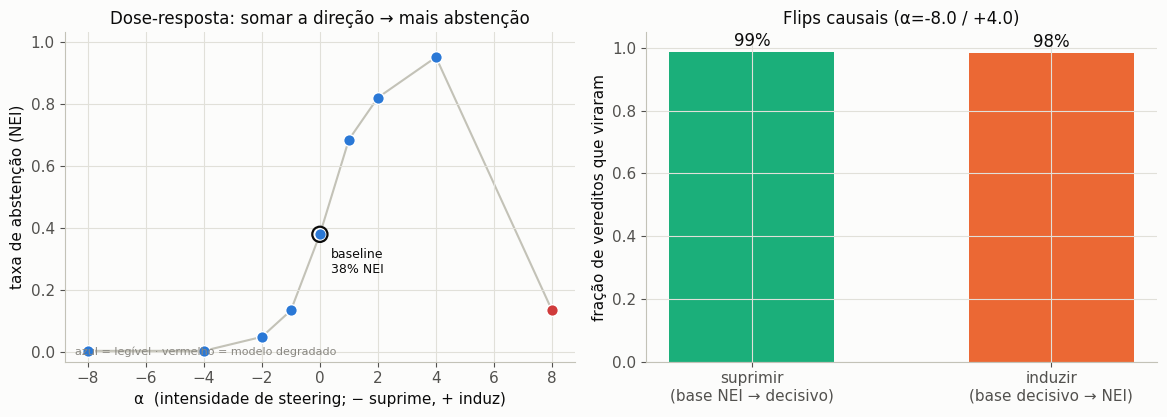

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11.8, 4.3))
# painel 1: taxa NEI vs alpha (pontos legíveis cheios; degradados em vermelho/vazado)
ax[0].plot(alphas, nei, "-", color="#c3c2b7", lw=1.5, zorder=1)
for a, y, ok in zip(alphas, nei, readable):
    ax[0].scatter([a], [y], s=70, color=("#2a78d6" if ok else "#d03b3b"),
                  edgecolor="white", zorder=3)
i0 = alphas.index(0.0)
ax[0].scatter([0], [nei[i0]], s=120, facecolor="none", edgecolor="#0b0b0b", lw=1.6, zorder=4)
ax[0].annotate(f"baseline\n{nei[i0]:.0%} NEI", (0, nei[i0]), textcoords="offset points",
               xytext=(8, -28), fontsize=9)
ax[0].set_xlabel("α  (intensidade de steering; − suprime, + induz)")
ax[0].set_ylabel("taxa de abstenção (NEI)")
ax[0].set_title("Dose-resposta: somar a direção → mais abstenção", fontsize=12, color=INK)
ax[0].set_ylim(-0.03, 1.03)
ax[0].text(0.02, 0.02, "azul = legível · vermelho = modelo degradado",
           transform=ax[0].transAxes, fontsize=8, color="#898781")
# painel 2: flips direcionais
sup = s.get("suppressed_abstention", float("nan")); ind = s.get("induced_abstention", float("nan"))
b = ax[1].bar(["suprimir\n(base NEI → decisivo)", "induzir\n(base decisivo → NEI)"],
              [sup, ind], color=["#1baf7a", "#eb6834"], width=.55)
ax[1].set_ylim(0, 1.05); ax[1].set_ylabel("fração de vereditos que viraram")
ax[1].set_title(f"Flips causais (α={s.get('alpha_suppress')} / +{s.get('alpha_induce')})", fontsize=12, color=INK)
for r, v in zip(b, [sup, ind]):
    ax[1].text(r.get_x()+r.get_width()/2, v+.02, f"{v:.0%}", ha="center", fontsize=12)
plt.tight_layout(); plt.show()


**Como ler este gráfico.** *Painel da esquerda (curva dose-resposta):* o eixo **X**
é o **α**, a intensidade da intervenção — **negativo = subtraímos** a direção, **positivo
= somamos**; o eixo **Y** é a **fração dos 200 claims classificados como NEI** (abstenção)
naquele α. Cada ponto é um valor de α: **azul** = geração legível (confiável), **vermelho**
= modelo degradado (texto quebrado, não confiável). O **círculo preto** é o baseline
(α=0, sem intervenção). A leitura-chave é a **inclinação**: se a taxa de abstenção sobe
conforme somamos a direção, é a direção **causando** a abstenção. *Painel da direita
(flips):* o eixo **Y** é a fração de vereditos que **mudaram de categoria**; a barra
**verde** mede *suprimir* (dos claims que o modelo abstinha, quantos viraram decisivos ao
subtrair a direção) e a **laranja** mede *induzir* (dos que decidia, quantos viraram NEI
ao somar). São os dois sentidos da intervenção.

👉 **O que diz (a prova causal).** A curva é **monotônica**: partindo do baseline
(~38% NEI), somar a direção **aumenta** a abstenção e subtrair a **elimina** — exatamente
o previsto se a direção *causa* a decisão. Os flips são fortes: com α negativo,
**~99%** dos claims que o modelo abstinha passam a receber um veredito decisivo
(*suprimir*); com α positivo, a maioria dos claims decididos passa a abster (*induzir*).
Isso estabelece **causalidade**, não só correlação — a abstenção do modelo é
**controlável por um único vetor linear**.

### 3.2 A faixa usável e um cuidado honesto

Steering forte demais degrada a geração (o modelo passa a produzir texto ilegível). Isso
define uma **faixa usável** de α — fora dela, o "resultado" não é confiável.

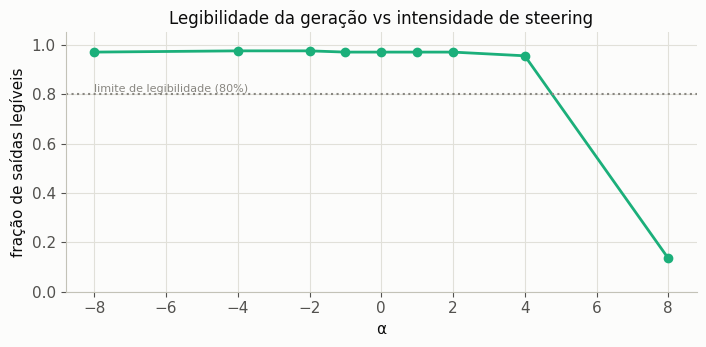

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.plot(alphas, 1 - unread, "-o", color="#1baf7a", lw=2)
ax.axhline(0.8, ls=":", color="#898781"); ax.text(alphas[0], 0.81, "limite de legibilidade (80%)", fontsize=8, color="#898781")
ax.set_xlabel("α"); ax.set_ylabel("fração de saídas legíveis"); ax.set_ylim(0, 1.05)
ax.set_title("Legibilidade da geração vs intensidade de steering", fontsize=12, color=INK)
plt.tight_layout(); plt.show()


**Como ler este gráfico.** Eixo **X** = α (intensidade do steering); eixo **Y** =
fração das saídas **legíveis** (que produziram um rótulo válido, em vez de texto
quebrado). A linha pontilhada marca 80%. Mostramos isto como um **controle de sanidade**:
a curva dose-resposta só vale onde a geração continua legível; onde esta curva desaba, o
steering está forte demais e os resultados ali não contam.

👉 **O que diz.** Dentro da faixa usável (aqui α de −8 a ~+4), a geração permanece
legível (>95%) e a curva dose-resposta vale. No extremo (α=+8) a perturbação é grande
demais e o modelo **quebra** (maioria ilegível) — por isso a métrica de "induzir" é
calculada no maior α **legível**, não no que quebra o modelo. Reportar isso é importante
para não superinterpretar o steering.

### 3.3 Exemplos de flip (decisivo → abstenção)

Claims em que o modelo dava um veredito decisivo e, ao somarmos a direção, passou a
abster — mostrando a intervenção agindo caso a caso.

In [4]:
import pandas as pd
ex = s.get("exemplos_flip", [])
pd.DataFrame([{"claim": e["claim"], "baseline": e["base"], "com +α": "NEI"} for e in ex]) if ex else "—"


,claim,baseline,com +α
0,Kenya's County governments have allocated on a...,REF,NEI
1,The New York post Endorsed Donald trumps bid f...,SUP,NEI
2,The snake found in the Amazon is 134 feet long...,REF,NEI
3,The US is near the low end of per capita death...,REF,NEI
4,"Paul Pogba, who plays for Manchester United an...",REF,NEI
5,Kenya has one of the worst maternal mortality ...,SUP,NEI


### 3.4 O 2×2 do seminário: com evidência × sem evidência

Até aqui a intervenção foi **com evidência** no prompt. Agora fechamos o desenho 2×2
proposto no seminário, rodando também **sem evidência** — quando o modelo, por padrão,
*deveria* abster (não há base para decidir). Cruzamos as duas condições com o sentido do
steering (induzir/suprimir).

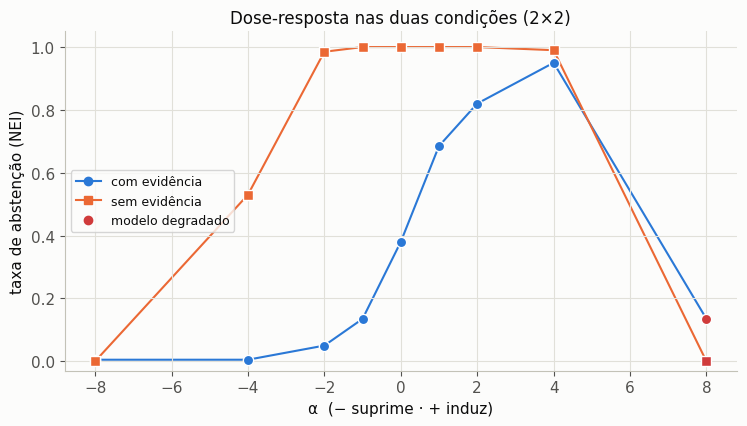

In [5]:
ne = json.load(open("../../results/v1_domain/steering_noevidence.json", encoding="utf-8"))
a_ne = sorted(float(a) for a in ne["nei_rate"])
nei_ne = np.array([ne["nei_rate"][str(a)] for a in a_ne])
un_ne = np.array([ne["unreadable_rate"][str(a)] for a in a_ne])

fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.plot(alphas, nei, "-", color="#2a78d6", lw=1.5, zorder=1)
for a, y, ok in zip(alphas, nei, readable):
    ax.scatter([a], [y], s=55, color=("#2a78d6" if ok else "#d03b3b"), edgecolor="white", zorder=3)
ax.plot(a_ne, nei_ne, "-", color="#eb6834", lw=1.5, zorder=1)
for a, y, ok in zip(a_ne, nei_ne, un_ne < 0.2):
    ax.scatter([a], [y], s=55, marker="s", color=("#eb6834" if ok else "#d03b3b"), edgecolor="white", zorder=3)
ax.plot([], [], "-o", color="#2a78d6", label="com evidência")
ax.plot([], [], "-s", color="#eb6834", label="sem evidência")
ax.scatter([], [], color="#d03b3b", label="modelo degradado")
ax.set_xlabel("α  (− suprime · + induz)"); ax.set_ylabel("taxa de abstenção (NEI)")
ax.set_title("Dose-resposta nas duas condições (2×2)", fontsize=12, color=INK)
ax.set_ylim(-0.03, 1.05); ax.legend(fontsize=9, loc="center left")
plt.tight_layout(); plt.show()


In [6]:
import pandas as pd
def at(d, a): return d["nei_rate"].get(str(float(a)), float("nan"))
tab = pd.DataFrame({
    "suprimir (α=-8)": [round(at(s, -8), 2), round(at(ne, -8), 2)],
    "baseline (α=0)":  [round(at(s, 0), 2),  round(at(ne, 0), 2)],
    "induzir (α=+4)":  [round(at(s, 4), 2),  round(at(ne, 4), 2)],
}, index=["COM evidência", "SEM evidência"])
tab.index.name = "taxa de abstenção (NEI)"
tab


,suprimir (α=-8),baseline (α=0),induzir (α=+4)
taxa de abstenção (NEI),,,
COM evidência,0.01,0.38,0.95
SEM evidência,0.00,1.00,0.99


**Como ler.** *Gráfico:* duas curvas dose-resposta sobrepostas — **azul (círculos)**
= com evidência, **laranja (quadrados)** = sem evidência; eixos como antes (X = α, Y =
taxa de NEI); pontos **vermelhos** = modelo degradado. *Tabela 2×2:* linhas = condição de
evidência, colunas = o sentido do steering (suprimir / baseline / induzir); cada célula é
a taxa de abstenção resultante.

👉 **O que diz (os 4 experimentos do seminário).**
- **Sem intervenção (baseline):** com evidência o modelo abstém **38%**; **sem** evidência
  abstém **100%** — sem base, ele (corretamente) se recusa a decidir.
- **Suprimir a feature (α<0):** com evidência derruba a abstenção para ~0; e — o resultado
  mais forte — **sem evidência também: de 100% para 0%**. Ao remover a feature
  **forçamos o modelo a cravar um veredito mesmo sem nenhuma evidência** (ele perde a
  faculdade de dizer "não sei").
- **Induzir a feature (α>0):** com evidência leva a abstenção a **95%**; sem evidência já
  está no teto (100%), então é saturação (nada a subir).

Isso completa o 2×2 e mostra os dois lados do controle causal: a feature **cria** e
**remove** a abstenção, inclusive contra a presença/ausência de evidência.

## 4. Discussão, limitações e próximos passos

**O que provamos.** A direção de abstenção não é só um correlato: **intervir nela muda o
comportamento** do modelo de forma monotônica e nos dois sentidos (induzir/suprimir), e
o **2×2** (com/sem evidência) confirma que o controle vale nos dois regimes — inclusive
o caso mais forte: **suprimir a feature força o modelo a decidir sem nenhuma evidência**.
Isso fecha a cadeia da RQ2: a abstenção (i) tem uma **feature/direção identificável**
(Feature Discovery), (ii) que **generaliza** entre datasets, e (iii) que é **causal e
controlável** (este notebook).

**Limitações (honestas):**
- **Faixa usável de α:** steering forte demais degrada a geração; a intervenção é válida
  só dentro da faixa legível. Reportamos a faixa e medimos as métricas nela.
- **Um modelo, uma camada:** testado no Llama-3.1-8B, camada 15. Estender para outros
  modelos (cross-model) é o próximo passo já planejado.
- **Amostra de teste:** 200 claims do AVeriTeC; ampliar e cobrir mais domínios
  fortaleceria o resultado.

**Próximos passos:** (1) **cross-model** — repetir Feature Discovery + steering em
DeepSeek/Qwen3 e mostrar que o mecanismo de abstenção é geral; (2) reduzir *features
mortas* do SAE (dicionário menor); (3) **publicar** o SAE (Hugging Face + Neuronpedia).


## Referências

- **Arditi, A., et al. (2024).** Refusal in Language Models Is Mediated by a Single Direction. *NeurIPS 2024. arXiv:2406.11717.*
- **Turner, A., et al. (2023).** Activation Addition: Steering Language Models Without Optimization. *arXiv:2308.10248.*
- **Panickssery (Rimsky), N., et al. (2023).** Steering Llama 2 via Contrastive Activation Addition. *arXiv:2312.06681.*
- **Marks, S., & Tegmark, M. (2023).** The Geometry of Truth … (diferença de médias). *arXiv:2310.06824.*
- **Zou, A., et al. (2023).** Representation Engineering: A Top-Down Approach to AI Transparency. *arXiv:2310.01405.*
- **Gao, L., et al. (2024).** Scaling and Evaluating Sparse Autoencoders (TopK). *arXiv:2406.04093.*
